# 06 · The 2026 SEA Boom Radar

This applies the backtested machinery to **today's** candidates, using data to September 2026.

For each candidate we answer three questions:
1. **Is it a real trend in SF?** Method A, Method B, and whether they agree.
2. **Where is SEA in the cycle?** SEA search momentum (rising, flat or falling) and SEA's
   level relative to its own peak.
3. **When could SEA follow?** The lag estimated from historical SF→SEA transfers (notebook 05),
   replaced by a sector-specific Granger estimate when that estimate is significant.

The output is a ranked radar and a quadrant chart. **This is a screening tool, not
an investment recommendation.** Read it together with notebook 05: the composite scores did **not** pass
the backtest, so the most useful column here is `sync`, the SF-SEA same-month correlation.
Low or negative sync means SEA isn't just echoing the SF news cycle, which is the pattern past booms showed.

**Data caveat:** Google Trends rate-limited this run, so most candidates use Wikipedia pageviews
(English vs SEA languages, 2015 onward) as the attention series. See `attention_source`. Re-run
notebook 01 onward after `python -m radar.fetch gtrends` completes for the Google-Trends version.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import PROC, FIG, SECTORS, CANDIDATES, LABELLED, END_YEAR, ROOT
warnings.filterwarnings("ignore")

A = pd.read_parquet(PROC / "method_A_scores.parquet")
B = pd.read_parquet(PROC / "method_B_scores.parquet")
B3 = pd.read_parquet(PROC / "method_B3_transfer.parquet")
lead = pd.read_parquet(PROC / "backtest_lead.parquet")
sectors = pd.read_parquet(PROC / "sectors.parquet")
yearly = pd.read_parquet(PROC / "panel_yearly.parquet")
wb = pd.read_parquet(PROC / "worldbank.parquet")
gt_meta = pd.read_parquet(PROC / "gt_meta.parquet")
df = A.merge(B[["sector", "year", "score_B", "score_B1", "score_B2"]], on=["sector", "year"])
df["ensemble"] = df[["score_A", "score_B"]].mean(axis=1)

## 1 · Turning scores into historical hit-rates
A score of 0.62 means nothing to an investor on its own. So we fit an isotonic (monotone)
mapping from ensemble score to **the share of labelled sector-years at that score
level that became SEA booms**. N is small, so treat it as a rough guide.

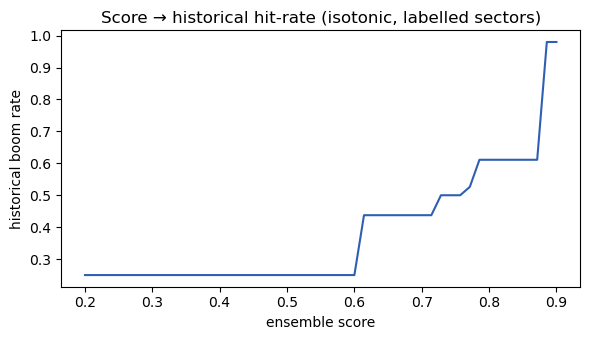

In [2]:
ev = pd.read_parquet(PROC / "backtest_eval_set.parquet")          # the decision-window rows from notebook 05
iso = IsotonicRegression(y_min=0.02, y_max=0.98, out_of_bounds="clip").fit(ev.ensemble, (ev.label == "boom").astype(int))
xs = np.linspace(0.2, 0.9, 50)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xs, iso.predict(xs), color="#2f5fb3"); ax.set_xlabel("ensemble score"); ax.set_ylabel("historical boom rate")
ax.set_title("Score → historical hit-rate (isotonic, labelled sectors)")
plt.tight_layout(); plt.show()

## 2 · SEA phase and timing

In [3]:
def yser(s, sig):
    x = yearly[(yearly.sector == s) & (yearly.signal == sig)].set_index("year")["value"].sort_index()
    return x[x.index <= END_YEAR]

def g2(x, t=END_YEAR):
    x = x.reindex(range(t - 3, t + 1))
    if x.isna().sum() > 1 or x.max() <= 0: return np.nan
    e = 0.05 * x.max()
    return float(np.log((x.loc[[t - 1, t]].mean() + e) / (x.loc[[t - 3, t - 2]].mean() + e)))

hist_lag_years = float(np.nanmedian(B3.loc[B3.label == "boom", "lag_months"])) / 12
print(f"Median SF->SEA lag across historical booms: {hist_lag_years:.1f} years")

def phase(sea_g, sea_hold):
    if np.isnan(sea_g): return "no SEA signal"
    if sea_g > 0.15: return "SEA rising now"
    if sea_g < -0.15: return "SEA fading"
    return "SEA mature/plateau" if sea_hold > 0.8 else "SEA not moving yet"

rows = []
for s in CANDIDATES + [k for k, v in SECTORS.items() if v["label"] == "ambiguous"]:
    cur = df[(df.sector == s) & (df.year == END_YEAR)].iloc[0]
    prev = df[(df.sector == s) & (df.year == END_YEAR - 1)].iloc[0]
    sea = yser(s, "gt_sea"); sf = yser(s, "gt_sf")
    sea_g = g2(sea); sea_hold = sea.iloc[-1] / sea.max() if len(sea) and sea.max() > 0 else np.nan
    sig_lag = B3.loc[s, "granger_p"] < 0.05 and B3.loc[s, "xcorr"] > 0.3
    lag_y = B3.loc[s, "lag_months"] / 12 if sig_lag else hist_lag_years
    rows.append(dict(sector=s, group=sectors.label[s],
                     score_A=cur.score_A, score_B=cur.score_B, ensemble=cur.ensemble,
                     delta_vs_2025=cur.ensemble - prev.ensemble,
                     agree="yes" if (cur.score_A >= 0.5) == (cur.score_B >= 0.5) else "NO",
                     hist_hit_rate=float(iso.predict([cur.ensemble])[0]) if not np.isnan(cur.ensemble) else np.nan,
                     sf_growth_2y=g2(sf), sea_growth_2y=sea_g, sea_vs_peak=sea_hold,
                     sea_phase=phase(sea_g, sea_hold), lag_source="sector Granger" if sig_lag else "historical median",
                     est_lag_years=lag_y,
                     breadth=cur.breadth, substance=cur.substance, low_spike=cur.low_spike, diffusion=cur.diffusion,
                     sync=cur.sync, attention_source=gt_meta.loc[s].get('gt_sf_source', 'google trends')))
R = pd.DataFrame(rows).set_index("sector").sort_values("ensemble", ascending=False)

def verdict(r):
    if np.isnan(r.ensemble): return "insufficient data"
    if r.ensemble >= 0.55 and r.agree == "yes":
        return {"SEA not moving yet": "EARLY WINDOW: real SF trend, SEA hasn't moved",
                "SEA rising now": "TRANSFERRING NOW: SEA catching up",
                "SEA mature/plateau": "ALREADY HERE: SEA largely caught up",
                "SEA fading": "Real in SF, SEA cooling: check local fit",
                "no SEA signal": "Real in SF, no SEA demand signal yet"}[r.sea_phase]
    if r.ensemble >= 0.55: return "PROMISING, methods disagree: diligence"
    if r.ensemble >= 0.45: return "WATCHLIST: mixed evidence"
    return "LIKELY NOISE / not yet a trend"
R["verdict"] = R.apply(verdict, axis=1)
R.to_csv(ROOT / "reports" / "radar_2026.csv")
R[["group", "score_A", "score_B", "ensemble", "sync", "hist_hit_rate", "sea_phase", "attention_source", "verdict"]].round(2)

Median SF->SEA lag across historical booms: 0.8 years


,group,score_A,score_B,ensemble,sync,hist_hit_rate,sea_phase,attention_source,verdict
sector,,,,,,,,,
prediction_markets,candidate,0.79,0.77,0.78,NaN,0.61,no SEA signal,wikipedia (wiki_en_share),"Real in SF, no SEA demand signal yet"
ai_datacenters,candidate,0.80,0.73,0.77,-0.16,0.50,SEA fading,wikipedia (wiki_en_share),"Real in SF, SEA cooling: check local fit"
generative_ai,candidate,0.65,0.78,0.72,NaN,0.44,SEA rising now,wikipedia (wiki_en_share),TRANSFERRING NOW: SEA catching up
social_commerce,candidate,0.61,0.69,0.65,-0.02,0.44,SEA fading,wikipedia (wiki_en_share),"Real in SF, SEA cooling: check local fit"
ai_healthcare,candidate,0.67,0.55,0.61,NaN,0.25,no SEA signal,wikipedia (wiki_en_share),"Real in SF, no SEA demand signal yet"
stablecoins,candidate,0.61,0.59,0.60,0.78,0.25,SEA rising now,wikipedia (wiki_en_share),TRANSFERRING NOW: SEA catching up
agritech,candidate,0.54,0.65,0.59,NaN,0.25,no SEA signal,wikipedia (wiki_en_share),"Real in SF, no SEA demand signal yet"
smb_vertical_saas,candidate,0.53,0.65,0.59,NaN,0.25,no SEA signal,wikipedia (wiki_en_share),"Real in SF, no SEA demand signal yet"
carbon_markets,candidate,0.56,0.62,0.59,0.17,0.25,SEA fading,wikipedia (wiki_en_share),"Real in SF, SEA cooling: check local fit"


## 3 · The radar chart
* **x-axis:** how real the trend is in SF (ensemble of A and B, 2026)
* **y-axis:** SEA's 2-year search momentum
* **Bottom-right = the opportunity zone.** The trend is real in SF and SEA hasn't caught up
  yet. That is the pattern ride-hailing (2013), digital payments (2015) and BNPL (2018) showed
  before their SEA booms.

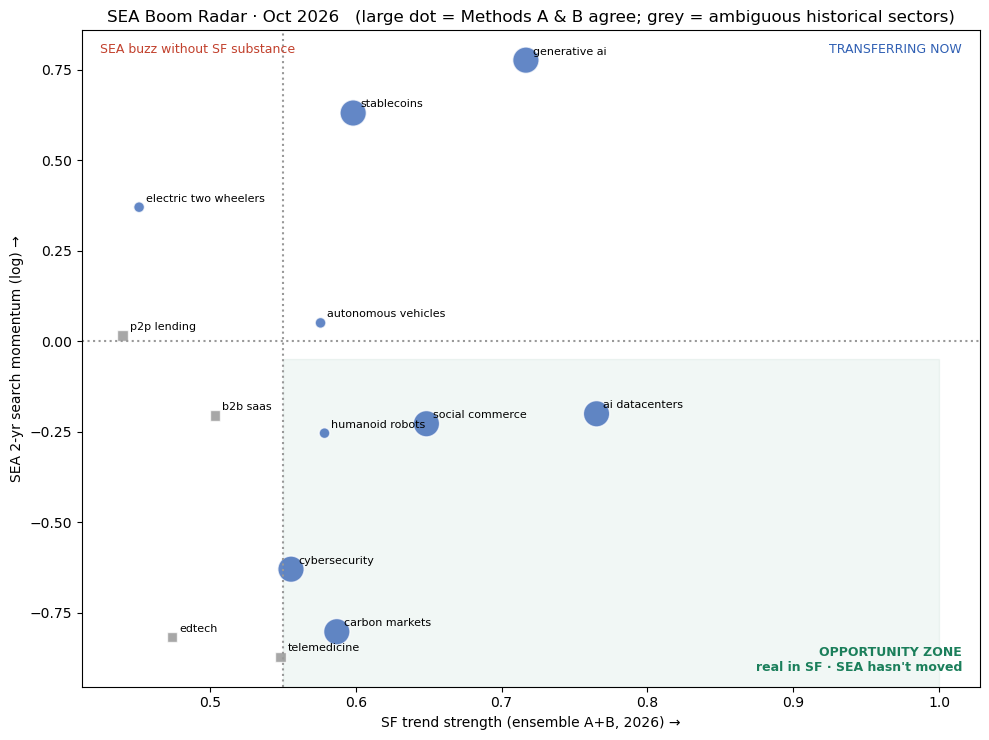

In [4]:
fig, ax = plt.subplots(figsize=(10, 7.5))
cand = R[R.group == "candidate"].dropna(subset=["ensemble"])
amb = R[R.group == "ambiguous"].dropna(subset=["ensemble"])
ax.axvspan(0.55, 1, ymin=0, ymax=0.5, color="#1b7f5b", alpha=0.06)
ax.axvline(0.55, color="#999", ls=":"); ax.axhline(0, color="#999", ls=":")
for d, c, mk in [(cand, "#2f5fb3", "o"), (amb, "#8a8a8a", "s")]:
    ax.scatter(d.ensemble, d.sea_growth_2y.clip(-1.5, 1.5), s=60 + 300 * (d.agree == "yes"),
               c=c, alpha=.75, marker=mk, edgecolor="white")
    for s, r in d.iterrows():
        ax.annotate(s.replace("_", " "), (r.ensemble, np.clip(r.sea_growth_2y, -1.5, 1.5)), fontsize=8,
                    xytext=(5, 4), textcoords="offset points")
ax.set_xlabel("SF trend strength (ensemble A+B, 2026) →"); ax.set_ylabel("SEA 2-yr search momentum (log) →")
ax.text(0.98, 0.02, "OPPORTUNITY ZONE\nreal in SF · SEA hasn't moved", transform=ax.transAxes,
        ha="right", va="bottom", color="#1b7f5b", fontsize=9, fontweight="bold")
ax.text(0.98, 0.98, "TRANSFERRING NOW", transform=ax.transAxes, ha="right", va="top", color="#2f5fb3", fontsize=9)
ax.text(0.02, 0.98, "SEA buzz without SF substance", transform=ax.transAxes, ha="left", va="top", color="#c2412d", fontsize=9)
ax.set_title("SEA Boom Radar · Oct 2026   (large dot = Methods A & B agree; grey = ambiguous historical sectors)")
plt.tight_layout(); plt.savefig(FIG / "06_radar_2026.png", dpi=160); plt.show()

## 4 · SEA readiness context (World Bank, latest year available)
These are the enabling conditions behind several theses. A *gap* can be an opportunity:
low account ownership, for example, is what made e-wallets and BNPL leapfrog cards in SEA.

In [5]:
latest = wb.sort_values("year").groupby(["country", "indicator"]).last()["value"].unstack()
latest[["internet_users_pct", "account_ownership_pct", "urban_pct", "gdp_pc_ppp", "electricity_access_pct"]].round(1)

indicator,internet_users_pct,account_ownership_pct,urban_pct,gdp_pc_ppp,electricity_access_pct
country,,,,,
IDN,72.8,56.3,59.4,15091.0,99.9
MYS,98.0,88.7,77.4,35461.4,100.0
PHL,67.3,50.2,55.8,10747.5,94.8
SGP,94.4,98.0,100.0,139592.6,100.0
THA,90.9,91.8,62.8,22431.8,100.0
USA,94.7,97.0,80.2,76931.3,100.0
VNM,84.2,70.6,38.8,15457.3,100.0


## 5 · Evidence cards for the top candidates

In [6]:
top = R[R.group == "candidate"].head(6)
top[["score_A", "score_B", "breadth", "substance", "low_spike", "diffusion",
     "sf_growth_2y", "sea_growth_2y", "sea_phase", "est_lag_years", "verdict"]].round(2).T

sector,prediction_markets,ai_datacenters,generative_ai,social_commerce,ai_healthcare,stablecoins
score_A,0.79,0.8,0.65,0.61,0.67,0.61
score_B,0.77,0.73,0.78,0.69,0.55,0.59
breadth,1.0,1.0,0.75,0.67,0.75,1.0
substance,0.54,0.55,0.36,0.8,0.62,0.52
low_spike,0.39,0.51,0.26,0.6,0.64,0.47
diffusion,NaN,1.0,NaN,1.0,NaN,0.22
sf_growth_2y,1.49,0.71,1.72,0.02,-0.17,1.1
sea_growth_2y,NaN,-0.2,0.78,-0.23,NaN,0.63
sea_phase,no SEA signal,SEA fading,SEA rising now,SEA fading,no SEA signal,SEA rising now
est_lag_years,0.83,0.83,0.83,0.83,0.83,0.83
